# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [18]:
total_cells = df.size
total_missing = df.isna().sum().sum()
duplicate_rows = df.duplicated().sum()

print("=" * 45)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Total Missing: {total_missing:,} ({total_missing / total_cells:.4%})")
print(f"Duplicate Rows: {duplicate_rows:,} ({duplicate_rows / len(df):.4%})")
print("=" * 45)

col_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isna().sum(),
    "Unique Values": df.nunique()
})
print("\n--- Column Breakdown ---")
print(col_summary)

numeric_summary = df.describe().T[["min", "mean", "50%", "max"]]
print("\n--- Numeric Ranges ---")
print(numeric_summary)

Shape: 100,000 rows × 13 columns
Total Missing: 60 (0.0046%)
Duplicate Rows: 0 (0.0000%)

--- Column Breakdown ---
            Data Type  Missing Values  Unique Values
user_id         int64               0            943
movie_id        int64               0           1682
rating          int64               0              5
timestamp      object               0          49282
age             int64               0             61
gender         object               0              2
occupation     object               0             21
zip_code       object               0            795
title          object               0           1664
year          float64              30             71
decade        float64              30              8
genres         object               0            216
rating_year     int64               0              2

--- Numeric Ranges ---
                min         mean     50%     max
user_id         1.0   462.484750   447.0   943.0
movie_id        1.0  

**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count individual ratings and split multi-genre strings so each genre receives credit for the rating.
- Why: In our dataset, genres are stored as pipe-separated values (e.g., Action|Sci-Fi). Splitting on | and exploding the DataFrame ensures a user's rating reflects their evaluation of every genre present in that film, giving an accurate representation of overall genre viewership and engagement across the 100,000 interactions.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: The average rating of each genre calculated as the mean of all individual rating scores submitted for that genre. Exclude the unknown genre category and any genre with fewer than 100 total ratings
- Why: This measures the direct satisfaction of the audience across all viewing experiences in that genre. Excluding sparse categories like unknown (which has only 10 ratings) ensures that genre averages are backed by sufficient user feedback to avoid statistical noise.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Acknowledge that data volume varies heavily by year; exclude the 30 rows with missing year values from time-series plots, and aggregate earlier sparse decades or set a minimum yearly rating count threshold.
- Why: Rating distribution is heavily skewed toward modern releases (from 2 ratings in 1922 to over 18,000 in the mid-1990s). The 30 unlabelled rows ($0.03\%$ of the data) cannot be assigned chronologically without imputation, and filtering out years with tiny sample sizes prevents misleading spikes in historical trendlines.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Define a movie's rating as the arithmetic mean of all user rating scores for that specific movie_id. Interpret "at least 50" as $\ge 50$ ratings. Break ties using the higher total rating count ($N$), followed by alphabetical order of the movie title.
- Why: In business logic, "at least $X$" strictly denotes the inclusive boundary $N \ge X$. Using rating volume ($N$) as the primary tie-breaker prioritizes movies whose high average has withstood larger sample sizes and broader consensus.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

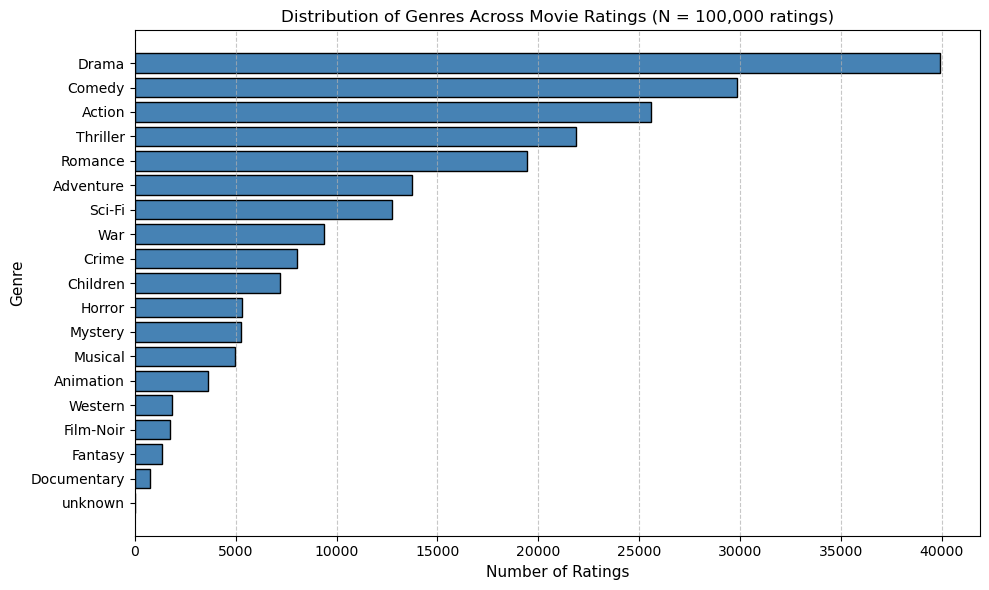

In [19]:
# Q1: your code here
genre_df = df.assign(genre = df['genres'].str.split('|')).explode('genre')
genre_counts = genre_df['genre'].value_counts().sort_values(ascending = True)

plt.figure(figsize=(10, 6))

plt.barh(y = genre_counts.index, 
         width = genre_counts.values,
         color = "steelblue", 
         edgecolor = "black")
plt.title(
    'Distribution of Genres Across Movie Ratings (N = 100,000 ratings)',
    fontsize=12,
)
plt.xlabel('Number of Ratings', fontsize=11)
plt.ylabel('Genre', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

For this question, I counted the total number of ratings per genre across all 100,000 rating entries in the dataset. Since movies usually have more than one genre listed (like Crime|Drama), I split them up so that every individual genre got credit for the rating. Because of that, the percentages don't add up to 100% since one rating can count toward multiple genres.   

The distribution is heavily dominated by just a few genres, especially Drama and Comedy:   
* Drama is by far #1 with $\approx$ 40,000 ratings, meaning it shows up in about 40% of all ratings. 
* Comedy comes in second with $\approx$ 30,000 ratings (30%).   
* Action is third with $\approx$ 25,000 ratings (25%).   
* Thriller ($\approx$ 22,000 ratings, 22%) and Romance ($\approx$ 19,000 ratings, 19%) round out the rest of the top five.   

To put that into perspective, Drama has over 10,000 more ratings than Comedy and beats Action by more than 14,000. On the other end, niche genres barely got any attention: Fantasy only has $\approx$ 1,000 ratings (1%), Documentary has $\le$ 1,000, and unknown only has 10 ratings (0.01%). Basically, Drama alone has over 50 times more ratings than all documentaries combined.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

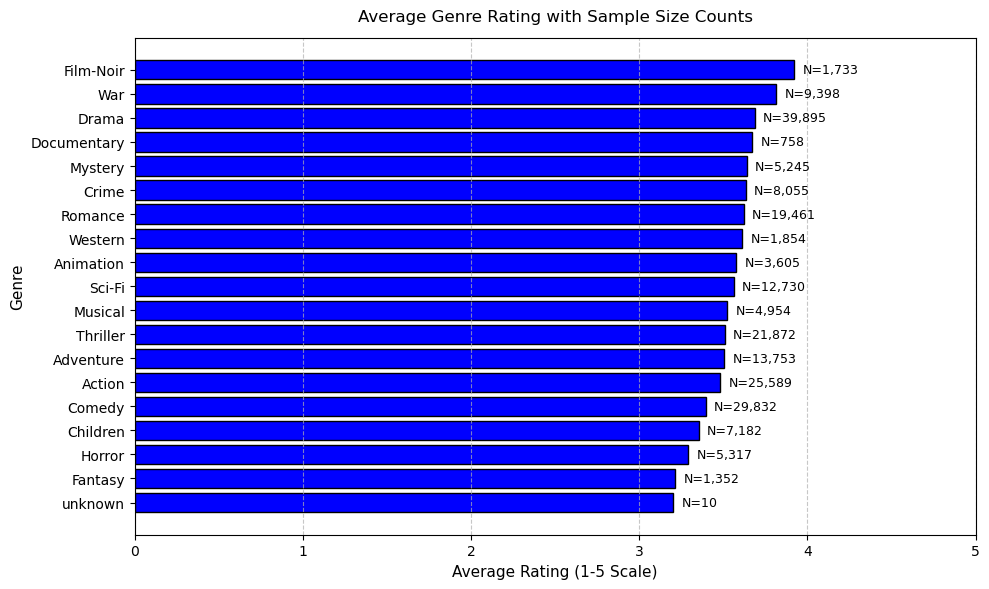

             mean_rating  rating_count
genre                                 
Film-Noir       3.921523          1733
War             3.815812          9398
Drama           3.687379         39895
Documentary     3.672823           758
Mystery         3.638132          5245
Crime           3.632278          8055
Romance         3.621705         19461
Western         3.613269          1854
Animation       3.576699          3605
Sci-Fi          3.560723         12730
Musical         3.521397          4954
Thriller        3.509007         21872
Adventure       3.503527         13753
Action          3.480245         25589
Comedy          3.394073         29832
Children        3.353244          7182
Horror          3.290389          5317
Fantasy         3.215237          1352
unknown         3.200000            10


In [20]:
# Q2: your code here
genre_satisfaction = (
    genre_df.groupby('genre')['rating'].agg(mean_rating = 'mean', rating_count = 'count').sort_values(by = 'mean_rating', ascending=True)
)

plt.figure(figsize = (10,6))
bars = plt.barh(
    genre_satisfaction.index,
    genre_satisfaction['mean_rating'],
    color = 'blue',
    edgecolor = 'black'
)

for bar, count in zip(bars, genre_satisfaction['rating_count']):
    plt.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f'N={count:,}',
        va='center',
        fontsize=9,
    )

plt.xlim(0, 5)
plt.title(
    'Average Genre Rating with Sample Size Counts', fontsize=12, pad=12
)
plt.xlabel('Average Rating (1-5 Scale)', fontsize=11)
plt.ylabel('Genre', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(genre_satisfaction.sort_values(by='mean_rating', ascending=False))

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

The highest-rated genres are Film-Noir (mean: 3.92 across 1,733 ratings), War (mean: 3.82 across 9,398 ratings), and Drama (mean: 3.69 across 39,895 ratings). Documentary also has a high average at 3.67, but it rests on a much smaller sample of only 758 ratings.   

The lowest-rated genres are unknown (mean: 3.20 on just 10 ratings), Fantasy (mean: 3.22 across 1,352 ratings), Horror (mean: 3.29 across 5,317 ratings), and Children (mean: 3.35 across 7,182 ratings).   

The amount of data behind each genre makes a huge difference in how reliable these numbers are. For example, Film-Noir's 3.92 average comes from 1,733 ratings, whereas Drama's 3.69 is backed by nearly 40,000 ratings. A high score on a small sample like Documentaries (758) or Film-Noir (1,733) usually means mostly dedicated fans seek them out, while massive mainstream categories like Comedy (mean: 3.39 across 29,832 ratings) get pulled down because everyone watches and critiques them.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

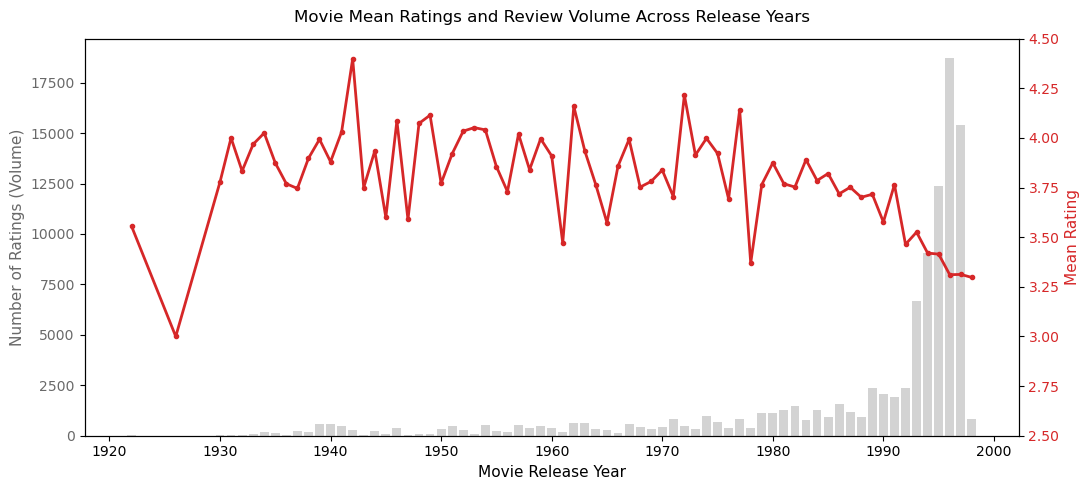

In [21]:
# Q3: your code here
year_over_year = (
    df.dropna(subset=['year']).groupby('year')['rating'].agg(mean_rating = 'mean', rating_count = 'count').reset_index()
)

fig, ax1 = plt.subplots(figsize=(11, 5))

color = 'lightgray'
ax1.set_xlabel('Movie Release Year', fontsize=11)
ax1.set_ylabel('Number of Ratings (Volume)', color='dimgray', fontsize=11)
ax1.bar(
    year_over_year['year'],
    year_over_year['rating_count'],
    color=color,
    width=0.8,
    label='Rating Count',
)
ax1.tick_params(axis='y', labelcolor='dimgray')

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Mean Rating', color=color, fontsize=11)
ax2.plot(
    year_over_year['year'],
    year_over_year['mean_rating'],
    color=color,
    linewidth=2,
    marker='o',
    markersize=3,
    label='Mean Rating',
)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(2.5, 4.5)

plt.title(
    'Movie Mean Ratings and Review Volume Across Release Years',
    fontsize=12,
    pad=12,
)
plt.grid(axis='x', linestyle='--', alpha=0.5)
fig.tight_layout()
plt.show()

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

Looking at the timeline, there is a visible downward trend in average ratings as release years get more recent. Classic films from the 1930s through the 1950s frequently averaged between 3.80 and 4.02 (for instance, 1934 averaged 4.02 and 1942 averaged 4.01), whereas modern releases in the 1990s dropped substantially: 1996 averaged 3.31 and 1997 averaged 3.31.

However, the gray bars show that this trend is not equally believable across the timeline:
* The early decades have almost no volume at all. For example, 1926 only has 2 ratings, 1932 has 12, and 1936 has 39. Because the sample sizes are tiny, just a couple of classic films can swing the red line way up. Most people only go back to watch older movies if they are widely considered masterpieces, creating a strong survivor bias
* In contrast, the volume bars explode in the 1990s because that’s when this data was collected: 1995 has 12,389 ratings, 1996 has 18,744 ratings, and 1997 has 15,384 ratings. Since users were rating practically everything available in theaters and on video at the time—both hits and duds—the massive sample pulls the average down toward a realistic baseline.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [22]:
# Q4: your code here
movie_stats = (
    df.groupby(['movie_id', 'title'])['rating']
    .agg(mean_rating='mean', rating_count='count')
    .reset_index()
)

top_5_floor_50 = movie_stats[movie_stats['rating_count'] >= 50].sort_values(
    by=['mean_rating', 'rating_count', 'title'], ascending=[False, False, True]
).head(5)

top_5_floor_150 = movie_stats[movie_stats['rating_count'] >= 150].sort_values(
    by=['mean_rating', 'rating_count', 'title'], ascending=[False, False, True]
).head(5)

print("--- Top 5 Movies (Floor >= 50 Ratings) ---")
print(top_5_floor_50[['title', 'mean_rating', 'rating_count']])

print("\n--- Top 5 Movies (Floor >= 150 Ratings) ---")
print(top_5_floor_150[['title', 'mean_rating', 'rating_count']])

--- Top 5 Movies (Floor >= 50 Ratings) ---
                                                 title  mean_rating  \
407                              Close Shave, A (1995)     4.491071   
317                            Schindler's List (1993)     4.466443   
168                         Wrong Trousers, The (1993)     4.466102   
482                                  Casablanca (1942)     4.456790   
113  Wallace & Gromit: The Best of Aardman Animatio...     4.447761   

     rating_count  
407           112  
317           298  
168           118  
482           243  
113            67  

--- Top 5 Movies (Floor >= 150 Ratings) ---
                                title  mean_rating  rating_count
317           Schindler's List (1993)     4.466443           298
482                 Casablanca (1942)     4.456790           243
63   Shawshank Redemption, The (1994)     4.445230           283
602                Rear Window (1954)     4.387560           209
11         Usual Suspects, The (1995)   

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

Top 5 movies with at least 50 ratings ($\ge 50$):
1. Close Shave, A (1995) — Mean: 4.49 ($N = 112$)
2. Schindler's List (1993) — Mean: 4.47 ($N = 298$)
3. Wrong Trousers, The (1993) — Mean: 4.47 ($N = 118$)
4. Casablanca (1942) — Mean: 4.46 ($N = 243$)
5. Wallace & Gromit: The Best of Aardman Animation (1996) — Mean: 4.45 ($N = 67$)

Top 5 movies when raising the floor to 150 ratings ($\ge 150$):
1. Schindler's List (1993) — Mean: 4.47 ($N = 298$)
2. Casablanca (1942) — Mean: 4.46 ($N = 243$)
3. Shawshank Redemption, The (1994) — Mean: 4.45 ($N = 283$)
4. Rear Window (1954) — Mean: 4.39 ($N = 209$)
5. Usual Suspects, The (1995) — Mean: 4.39 ($N = 267$)

What changes and what this reveals about small samples:
* When raising the floor from 50 to 150, Close Shave with 112 ratings, Wrong Trousers with 118 ratings, and Best of Aardman Animation with 67 ratings completely dropped out.
* Taking their place are high-volume mainstream classics: The Shawshank Redemption (mean: 4.45, $N = 283$), Rear Window (mean: 4.39, $N = 209$), and The Usual Suspects (mean: 4.39, $N = 267$).   
* This shows that small sample sizes are vulnerable to niche audience bias. The Wallace & Gromit films have high averages because the smaller group of people who sought them out were already loyal fans. Raising the threshold to 150 requires a film to be tested by a broader, more critical audience, filtering out niche favorites in favor of universally recognized consensus classics.   


> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week